# Simple Household Projection — PBA 2050+ Phased Headship Rates

Headship rates, or 
Applies headship rates to REMI population projections to forecast future households.  
Rates are phased from ACS 2018 toward Census 2000 levels between 2022–2037,
then held constant through 2050. They are binned into age / racial groups.

**Notebook structure**
1. Imports & configuration
2. Constants, mappings & scenario definitions
3. Helper functions
4. **Extract** — load raw data
5. **Transform** — bin & align data
6. **Load** — run projections, write CSVs
7. **Analysis** — topsheet, vacancies, unit forecast, Excel export
8. **QA** — inspection charts


## Methodology

### Approach
Households are projected by multiplying **household population** by **headship rates** — the fraction of people in each demographic cell who are heads of household. Population projections come from REMI PI; headship rates are estimated from PUMS microdata for several vintages and geographies.

---

### Step-by-step

| Step | What happens |
|------|-------------|
| 1. Load REMI population | Age × race/ethnicity × gender × subregion counts, by scenario, binned into 5-year age groups |
| 2. Remove group quarters | Census 2010 PUMS group-quarter rates (by age/race/gender) are applied to REMI totals to isolate the **household population** |
| 3. Apply headship rates | Household population × headship rate = projected households, summed to subregion |
| 4. Anchor to observed | DOF E-5 observed counts replace modelled values through **2022** |
| 5. Smooth transition | A sinusoidal easing function blends from a modest-growth baseline into the full REMI trajectory across the 2022–2035 window (see below) |
| 6. Assemble outputs | Results concatenated across all scenario × headship-rate combinations; CSV and Excel topsheets written |

---

### Data sources

| Dataset | Use | Coverage |
|---------|-----|----------|
| REMI PI — population by age / race / gender / subregion | Core population input | 2011–2050 (by scenario) |
| DOF E-5 estimates | Observed HH counts for early-year anchor | 1990–2023 |
| ABAG 1987 Projections | 1980 county HH counts (manually entered) | 1980 |
| Census 2010 PUMS | Group-quarter rates; 2010 base-year HH counts | 2010 |
| ACS 2014–2018 PUMS (Bay Area) | Latest refresh of headship rates | 2014–2018 |
| Census 2000 PUMS (Bay Area) | "Target" less-constrained headship rates | 2000 |
| ACS limited-universe vacancy rates | Vacancy baseline for unit projections | 2018 |

---

### Headship rate phasing *(ACS 2018 → Census 2000, Between the 2022–2037 period)*

The **phased** headship rate variant encodes the plan assumption that increased housing production will move the region toward an earlier, less housing-constrained environment. Rather than an abrupt shift, rates transition smoothly using a half-cosine:

$$HR(t) = HR_{\text{C2000}} + w(t)\cdot\bigl(HR_{\text{ACS18}} - HR_{\text{C2000}}\bigr)$$

where the blend weight $w(t)$ follows:

$$w(t) = \begin{cases} 1 & t < t_0 \\ \tfrac{1}{2}\cos\!\left(\dfrac{\pi\,(t-t_0)}{t_1-t_0}\right)+\tfrac{1}{2} & t_0 \le t < t_1 \\ 0 & t \ge t_1 \end{cases}$$

with $t_0 = 2022$, $t_1 = 2037$. Before 2022 the ACS 2018 rate applies in full; after 2037 the Census 2000 rate applies and is held constant through 2050.

---

### Smoothing the observed-to-modelled discontinuity *(around 2022)*

DOF-observed household counts are used through 2022. Because REMI's modelled population base can differ from DOF's (different benchmarks, reference dates), a direct splice often produces an artificial spike or drop in the year-over-year change series.

To prevent this a **second easing** blends from a *modest-growth baseline* into the full REMI projection:

- **Source series:** DOF observed counts through 2022, then extrapolated at **+0.8 %/yr** — a conservative near-term assumption.
- **Target series:** the full headship-rate-derived REMI projection.
- **Blend window:** source dominates through 2025 ($t_0 = 5$ years after 2020), then smoothly yields to REMI by 2035 ($t_1 = 15$ years after 2020).

The same half-cosine weight is used. The result is a household series with no discontinuous jump at the observed/modelled boundary, while still converging to the scenario trajectory in the medium term.

## 1 · Imports


In [86]:
import warnings
import os
import re
import fnmatch
import pathlib
from datetime import datetime

import numpy as np
import pandas as pd
import openpyxl

import seaborn as sns
import matplotlib.pyplot as plt
from pandas.api.types import CategoricalDtype

%matplotlib inline



## 2 · Configuration


In [87]:
# --- Display ---
pd.set_option('display.max_columns', 1800)
pd.set_option('display.width', 1800)
pd.options.display.float_format = '{:,.0f}'.format
warnings.filterwarnings('ignore')

# --- Plot style ---
sns.set(style='darkgrid')
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = [12, 7]


In [88]:
HOME_DIR = pathlib.Path.home()
# Box root differs by platform: a mounted drive on Windows, the Box-Box sync folder elsewhere.
BOX_DIR  = pathlib.Path('E:/Box') if os.name == 'nt' else HOME_DIR / 'Library/CloudStorage/Box-Box'
M_DRIVE  = pathlib.Path('/Volumes/Data/Models')


In [89]:
_REG = BOX_DIR / 'Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update'

INPUT_REMI_PATH     = _REG / 'REMI_raw_output'
INPUT_BASEDATA_PATH = _REG / 'household_forecast/base_data'
INPUT_MAPPINGS_PATH = _REG / 'mappings'

OUTPUT_PATH = _REG / 'household_forecast/output_v2'


## 3 · Constants, mappings & scenario definitions
Needs cleanup.

In [91]:
# --- Age breaks ---
breaks_5 = list(range(0, 86, 5)) + [float('inf')]
YEARS_FINE_MIDDLE = [0, 5] + list(range(20, 90, 5)) + [float('inf')]
YEARS_COARSE = [0, 15, 25, 65, float('inf')]

# --- Year-range helpers ---
def yrs(start, stop, step=5):
    """Inclusive year list from start to stop."""
    return list(range(start, stop + 1, step))

def strs(years):
    """String versions of a year list."""
    return list(map(str, years))

# --- Year range lists (int) ---
YEARS_5       = yrs(2010, 2050)
YEARS_5_2020  = yrs(2020, 2050)
YEARS_15_50   = yrs(2015, 2050)
YEARS_10_40   = yrs(2010, 2040)
YEARS_15_40   = yrs(2015, 2040)
YEARS_1       = yrs(2010, 2050, 1)
YEARS_5_00_50 = yrs(2000, 2050)
YEARS_5_2010  = yrs(2010, 2050)
YEARS_SELECT  = [2020, 2035, 2050]
YEARS_RHNA    = [2015, 2020] + yrs(2022, 2030, 1)

# --- String versions ---
YEARS_5_str       = strs(YEARS_5)
YEARS_15_50_str   = strs(YEARS_15_50)
YEARS_5_2020_str  = strs(YEARS_5_2020)
YEARS_1_str       = strs(YEARS_1)
YEARS_5_00_50_str = strs(YEARS_5_00_50)
YEARS_RHNA_str    = strs(YEARS_RHNA)

In [92]:
# --- Data dimension labels ---
grpqtrbins = ['YEAR', 'Region', 'gender', 'rac_ethn', 'age_grp_5']
agegrp = 'age_grp_5'
reg    = 'region'

# --- Easing: smooths observed-to-modelled transition ---
EASING_ENVELOPE_START = 2020   # first year of easing window
EASING_ENVELOPE_END   = 2050   # last year
EASING_T0 = 5                  # years after envelope start to begin blend
EASING_T1 = 15                 # years after envelope start to end blend

# --- Baseline series for easing source ---
BASE_SERIES_START = 2022       # last observed DOF year
BASE_SERIES_END   = 2050
BASE_GROWTH_RATE  = 1.008

# --- DOF observed data replaces modelled values through this year ---
DOF_END_OVERRIDE = 2022

# --- Headship rate variants to carry through the analysis ---
HR_KEEP     = ['Bay Area Census 2000', 'Bay Area ACS 12-16', 'Bay Area ACS 14-18', 'Bay Area ACS 18']
HR_TOPSHEET = 'HR Phased'


In [93]:
bayareafips_full = {
    '06001': 'Alameda',      '06013': 'Contra Costa', '06041': 'Marin',
    '06055': 'Napa',         '06075': 'San Francisco', '06081': 'San Mateo',
    '06085': 'Santa Clara',  '06097': 'Sonoma',        '06095': 'Solano',
}

remiregions = {
    'Alameda':       'East Bay',  'Contra Costa': 'East Bay',
    'Marin':         'West Bay',  'Napa':          'North Bay',
    'San Francisco': 'West Bay',  'San Mateo':     'West Bay',
    'Santa Clara':   'South Bay', 'Solano':        'North Bay',
    'Sonoma':        'North Bay',
}

bayarearegionsmtc = {
    4: 'Alameda', 5: 'Contra Costa', 3: 'Santa Clara',
    7: 'Napa',   2: 'San Mateo',    1: 'San Francisco',
    8: 'Sonoma', 9: 'Marin',        6: 'Solano',
}


In [94]:
scenarios = {
    'PBA_2040':               'PBA_2040',
    'R6H2C_COVID_cross_rev2': 'Blueprint-CV19 Plus Crossing',
    'REMI31_NC0_RC0_BASE':    'REMI 3.1 Standard Regional Control',
    'REMI31_NC0_RC0_FBP':     'REMI 3.1 Native FBP',
    'REMI31_NC1_RC1_FBP':     'REMI 3.1 Ported FBP',
    'REMI31_NC1_RC1_BASE':    'REMI 3.1 FBP Baseline',
    'REMI31_NC2_RC1_FBP':     'REMI 3.1 Ported FBP Emp relaxed',
    # 'REMI32_NC3_RC0_FBP':     'REMI 3.2 Ported FBP w/o RSQE / COVID updates, Census Mid',
    # 'REMI32_NC3_RC0':         'REMI 3.2 Census Mid RC',
}

BLUEPRINT_RUNS   = ['REMI31_NC1_RC1_FBP']
BLUEPRINT_AGGMAP = {'REMI31_NC1_RC1_FBP': 'Blueprint'}

# Each scenario's designated headship rate variant
scenario_to_headship_map = {
    'PBA_2040':               'HR PBA 2040',
    'R6H2C_COVID_cross_rev2': 'HR Phased',
    'REMI31_NC1_RC1_FBP':     'HR Phased',
    'REMI31_NC0_RC0_FBP':     'HR Phased',
    'REMI31_NC1_RC1_BASE':    'HR Bay Area ACS 14-18',
    'REMI31_NC0_RC0_BASE':    'HR Bay Area ACS 14-18',
    'REMI31_NC2_RC1_FBP':     'HR Phased',
    # 'REMI32_NC1_RC1_FBP':     'HR Phased',
    # 'REMI32_NC0_RC0_FBP':     'HR Phased',
    # 'REMI32_NC1_RC1_BASE':    'HR Bay Area ACS 14-18',
    # 'REMI32_NC0_RC0_BASE':    'HR Bay Area ACS 14-18',
    # 'REMI32_NC2_RC1_FBP':     'HR Phased',
    # 'REMI32_NC3_RC0_FBP':     'HR Phased',
}


## 4 · Helper functions


In [95]:
def pct(x):
    """Return fraction-of-total for a Series or DataFrame."""
    return x / x.sum()


def rounder(s, precision=3):
    """Round array to the nearest multiple of 10**precision."""
    factor = 10 ** precision
    return np.round(s / factor, 0) * factor


def agebreaker(breaks):
    """Compact age labels, e.g. 'age0004', 'age0509', 'age85p'."""
    labels = [
        'age{fr:02.0f}{to:02.0f}'.format(fr=breaks[f], to=breaks[f + 1] - 1)
        for f in range(len(breaks) - 1)
    ]
    labels[-1] = 'age{dt:,.0f}p'.format(dt=breaks[-2])
    return labels


def agebreaker2(breaks):
    """Readable age labels, e.g. 'Ages 25-29', 'Ages 85+'."""
    labels = [
        'Ages {fr:.0f}-{to:.0f}'.format(fr=breaks[f], to=breaks[f + 1] - 1)
        for f in range(len(breaks) - 1)
    ]
    labels[-1] = 'Ages {dt:,.0f}+'.format(dt=breaks[-2])
    return labels


# Derived age-group constants (depend on agebreaker2 and breaks_5)
SENIORS = agebreaker2(breaks_5)[-5:]
YOUNG   = agebreaker2(breaks_5)[5:9]


In [96]:
def easer(target_series, source_series, t_0=7, t_1=15,
          envelope_year_start=2015, envelope_year_end=2050):
    """
    Blend source_series into target_series using a sinusoidal easing function.

    Parameters
    ----------
    target_series, source_series : pd.DataFrame
        Both indexed by Year (int), columns = regions.
    t_0, t_1 : int
        Years after envelope_year_start where the blend begins / ends.
    envelope_year_start, envelope_year_end : int
        Year range of the output series.

    Returns
    -------
    pd.DataFrame  (Year columns as strings)
    """
    index = np.arange(envelope_year_end - envelope_year_start + 1)
    easing_window = t_1 - t_0
    x = np.pi * (index - t_0) / easing_window
    easing = 0.5 * np.cos(x) + 0.5
    easing[index < t_0]  = 1
    easing[index >= t_1] = 0

    easing = pd.Series(
        easing,
        index=pd.Index(np.arange(envelope_year_start, envelope_year_end + 1), name='Year'),
    )
    output = (source_series - target_series).mul(easing, axis=0) + target_series
    output = output.stack()
    output.name = 'value'
    return output.unstack('Year').rename(columns=str)


In [97]:
def process_taz_files(files):
    """
    Read TAZ summary CSVs and aggregate household counts by subregion.

    Parameters
    ----------
    files : list of pathlib.Path

    Returns
    -------
    pd.DataFrame  indexed by (HR, runid, Region) with Year columns
    """
    out = {}
    for f in files:
        if 'taz_summaries_2010.csv' not in f.name and 'taz_growth' not in f.name:
            yr = int(re.search(r'(?<=summaries_)\d{4}', f.name).group())
            out[yr] = pd.read_csv(f)

    tazdf = (
        pd.concat(out)
        .reset_index()
        .rename(columns={'level_0': 'year', 'level_1': 'rowid'})
    )
    tazdf = tazdf.rename(columns=str.lower)
    tazdf = tazdf.T.groupby(level=0).first().T
    tazdf['county'] = tazdf['county'].map(bayarearegionsmtc)
    tazdf['Region'] = tazdf['county'].map(remiregions)
    tazdf['Year']   = tazdf['year']

    pbadatasubreg = tazdf.groupby(['Year', 'Region'])[['tothh']].sum().reset_index()
    pbadatasubreg['HR']    = 'HR PBA 2040'
    pbadatasubreg['runid'] = 'PBA_2040'
    return (
        pbadatasubreg
        .set_index(['HR', 'runid', 'Region', 'Year'])
        .tothh
        .unstack('Year')
    )


In [98]:
def process_headship_data(input_basedata_path, age_breaks):
    """
    Load and filter the multi-region / multi-vintage headship rate file.

    Parameters
    ----------
    input_basedata_path : pathlib.Path or str
    age_breaks : list  (from agebreaker2)

    Returns
    -------
    pd.Series  indexed by (geovintage, rac_ethn, age_grp_5)
    """
    headship_alt = (
        pd.read_csv(
            pathlib.Path(input_basedata_path) / 'headship_stateregions_vintages.csv',
            index_col=['vintage', 'region', 'rac_ethn', 'age_grp_5'],
        )
        .value
        .fillna(0)
        .reset_index()
    )
    headship_alt['geovintage'] = headship_alt['region'] + ' ' + headship_alt['vintage']
    keep = [
        'Bay Area Census 2000', 'Rest of CA Census 2000',
        'Atlanta Regional ACS 12-16', 'Bay Area ACS 12-16',
        'Bay Area ACS 14-18', 'Bay Area ACS 18',
        'Rest of CA ACS 12-16', 'SANDAG ACS 12-16', 'SCAG ACS 12-16',
    ]
    headship_alt = headship_alt[headship_alt['geovintage'].isin(keep)]
    headship_alt['age_grp_5'] = headship_alt['age_grp_5'].astype(
        CategoricalDtype(categories=age_breaks, ordered=True)
    )
    return headship_alt.set_index(['geovintage', 'rac_ethn', 'age_grp_5'])['value']


In [99]:
def load_remi_pop_data(input_remi_path, scenarios, years_coarse, years_fine_middle, breaks_5):
    """
    Load REMI population Excel files and return a long-format DataFrame.

    Looks for 'A1 hhtot 1 subreg pop age race.xlsx' under
    input_remi_path / population / <scenario_key> /.

    Returns
    -------
    pd.DataFrame  with columns:
        runid, Region, rac_ethn, Year, sex, gender,
        age_coarse, age_fine, age_grp_5, value
    """
    matches = sorted(
        (pathlib.Path(input_remi_path) / 'population')
        .rglob('A1 hhtot 1 subreg pop age race.xlsx')
    )

    outdata = {}
    for fn in matches:
        raw = pd.read_excel(fn, engine='openpyxl')

        cat_row    = raw[raw.iloc[:, 0] == 'Category'].index[0]
        raw.columns = raw.iloc[cat_row]
        header_row = raw.iloc[:, 10].dropna().index[0]

        this_data = raw.iloc[header_row + 1:].copy()
        this_data.columns = raw.iloc[header_row].values
        this_data = this_data.rename(columns={'Age': 'Ages'})
        this_data = this_data[
            ~this_data['Ages'].str.contains('All Ages')
            & ~this_data['Race'].str.contains('All Races')
            & ~this_data['Gender'].str.contains('Total')
        ]
        this_data = (
            this_data
            .set_index(['Region', 'Race', 'Gender', 'Ages'])
            .filter(regex=r'\d{4}')
        )
        this_data.columns = this_data.columns.astype(int)
        print(fn)
        # Parent folder name is the scenario/run id, regardless of OS separator.
        outdata[fn.parent.name] = this_data

    outdata = pd.concat(outdata)
    remipop = (
        (outdata.stack() * 1000)
        .round(0)
        .astype(np.int32)
        .reset_index(name='value')
        .rename(columns={'Race': 'rac_ethn', 'level_5': 'Year', 'level_0': 'runid'})
    )
    remipop['sex']    = remipop['Gender'].str.lower()
    remipop['gender'] = remipop['Gender'] + 's'
    remipop['age_coarse'] = pd.cut(
        remipop['Ages'].str.extract(r'(\d{1,3})', expand=False).astype(int),
        right=False, bins=years_coarse, labels=agebreaker(years_coarse),
    ).astype(str)
    remipop['age_fine'] = pd.cut(
        remipop['Ages'].str.extract(r'(\d{1,3})', expand=False).astype(int),
        right=False, bins=years_fine_middle, labels=agebreaker(years_fine_middle),
    ).astype(str)
    remipop['age_grp_5'] = pd.cut(
        remipop['Ages'].str.extract(r'(\d{1,3})', expand=False).astype(np.int32),
        bins=breaks_5, labels=agebreaker2(breaks_5),
        include_lowest=True, right=False,
    )
    return remipop

In [100]:
def create_easing_base_series(envelope_year_start, envelope_year_end,
                              base_growth_rate, hhs_observed):
    """
    Build an observed-then-extrapolated baseline for the easing function.

    Uses actual DOF counts up to envelope_year_start, then projects
    forward at base_growth_rate per year.

    Parameters
    ----------
    envelope_year_start : int   Last year with observed DOF data.
    envelope_year_end   : int   Final year of the output series.
    base_growth_rate    : float Annual growth factor after start year.
    hhs_observed        : pd.DataFrame  Indexed by Region, integer year columns.

    Returns
    -------
    pd.DataFrame  indexed by Year (int), columns = regions
    """
    projected = {
        yr: hhs_observed[envelope_year_start]
            * (base_growth_rate ** (yr - envelope_year_start))
        for yr in range(envelope_year_start, envelope_year_end + 1)
    }
    projected_df = pd.concat(projected, names=['Year']).unstack('Region')
    source = pd.concat([
        hhs_observed.T,
        projected_df.loc[envelope_year_start + 1 :],
    ])
    source.index = pd.Index(map(int, source.index), dtype=int, name='Year')
    return source


In [101]:
def project_households(
    scenarios,
    remipop_binned,
    grp_qtr_shares,
    hsr,
    hhs_observed,
    source_series,
    reg,
    agegrp,
    output_path,
    input_basedata_path,
    easing_t0=5,
    easing_t1=15,
    easing_envelope_start=2020,
    easing_envelope_end=2050,
    dof_end_override=2022,
):
    """
    Project households for all scenarios x headship rate variants.

    For each (scenario, headship rate) pair:
      1. Subtract group-quarter population from REMI total.
      2. Multiply household population by headship rates.
      3. Override early years with DOF observed counts.
      4. Apply sinusoidal easing across the observed-to-modelled boundary.
      5. Write per-scenario CSVs.

    Parameters
    ----------
    scenarios           : dict  {abbrev: name}
    remipop_binned      : pd.DataFrame
    grp_qtr_shares      : pd.Series  Census 2010 group-quarter fractions
    hsr                 : dict  {label: headship rate Series}
    hhs_observed        : pd.DataFrame  DOF observed HH counts by region/year
    source_series       : pd.DataFrame  Easing baseline (create_easing_base_series)
    reg                 : str  Geographic label for filenames
    agegrp              : str  Age-group label for filenames
    output_path         : Path or str
    input_basedata_path : Path or str
    easing_t0/t1        : int  Easing window edges (years after envelope start)
    easing_envelope_start/end : int
    dof_end_override    : int  Replace modelled values through this year

    Returns
    -------
    tuple: hhallscenarios, hhallscenarios_age, hheaseallscenarios,
           hhsizescenarios, hhsizescenarios_subreg, hhpopallscenarios
    """
    hhproj_out        = {}
    hhproj_age_out    = {}
    hhproj_eased_out  = {}
    hhpop_out         = {}
    avg_hh_sz_out     = {}
    avg_hh_sz_reg_out = {}

    hhtot_binned_2010 = pd.read_csv(
        pathlib.Path(input_basedata_path)
        / ('census2010pums%s_%s_hhtot_binned.csv' % (reg, agegrp)),
        index_col=['Region', 'gender', 'rac_ethn', 'age_grp_5'],
    )['2010']

    for scen_abbrev, scen in scenarios.items():
        print(scen_abbrev)
        out_dir = pathlib.Path(output_path) / scen_abbrev
        out_dir.mkdir(parents=True, exist_ok=True)

        gqpop = (
            remipop_binned.loc[scen_abbrev]
            .stack()
            .mul(grp_qtr_shares, axis=0)
            .unstack('Year')
        )
        hhpop = remipop_binned.loc[scen_abbrev] - (
            remipop_binned.loc[scen_abbrev]
            .loc[grp_qtr_shares.index]
            .mul(grp_qtr_shares, axis=0)
            .stack()
            .round(0)
            .astype(np.int64)
            .unstack('Year')
        )
        hhpop_out[scen_abbrev] = hhpop

        for hrname, hr in hsr.items():
            lvls = list(hr.index.names)
            print('\t' + hrname)

            if 'Year' in hr.index.names:
                hhpop_proj = (
                    hhpop.stack()
                    .groupby(level=list(set(['Region', 'Year'] + lvls)))
                    .sum()
                    .reorder_levels(['rac_ethn', 'age_grp_5', 'Year', 'Region'])
                )
                household_projections = (
                    hr.reorder_levels(['rac_ethn', 'age_grp_5', 'Year'])
                    .mul(hhpop_proj)
                    .groupby(level=['Region'] + lvls)
                    .sum()
                    .unstack('Year')
                )
                lvls.remove('Year')
            else:
                household_projections = (
                    hhpop.fillna(0)
                    .groupby(level=['Region'] + lvls)
                    .sum()
                    .mul(hr, axis=0)
                )

            hhproj_age_out[(hrname, scen_abbrev)] = household_projections
            household_projections = (
                household_projections.fillna(0).groupby(level='Region').sum()
            )
            household_projections.update(hhs_observed)

            target_series = household_projections.T
            target_series.index = target_series.index.astype(int)
            household_projections_eased = easer(
                target_series=target_series,
                source_series=source_series,
                t_0=easing_t0,
                t_1=easing_t1,
                envelope_year_start=easing_envelope_start,
                envelope_year_end=easing_envelope_end,
            )

            hh2010 = hhtot_binned_2010.groupby(level='Region').sum().to_frame(name=2010)
            household_projections_w_2010 = pd.concat(
                [hh2010, household_projections], axis=1
            )
            household_projections_w_2010_eased = pd.concat(
                [hh2010, household_projections_eased], axis=1
            )

            hhpopsum = hhpop.fillna(0).groupby(level=['Region'] + lvls).sum()
            avg_hh_sz_out[(hrname, scen_abbrev)] = (
                hhpopsum.groupby(level=0).sum()
                .div(household_projections_w_2010.groupby(level=0).sum())
            )
            avg_hh_sz_reg_out[(hrname, scen_abbrev)] = pd.DataFrame(
                hhpopsum.sum().div(household_projections_w_2010.sum())
            ).T

            hhproj_out[(hrname, scen_abbrev)]       = household_projections_w_2010
            hhproj_eased_out[(hrname, scen_abbrev)] = household_projections_w_2010_eased

            slug = scen_abbrev + '_' + hrname.replace(' ', '_').replace('-', '_')
            now  = datetime.now()
            household_projections_w_2010.to_csv(
                out_dir / ('proj_%s_hh_sc_%s_%s.csv' % (reg, slug, now.strftime('%Y%m%d_%H%M%S')))
            )
            household_projections_w_2010_eased.to_csv(
                out_dir / ('proj_%s_hh_sc_%s_eased_%s.csv' % (reg, slug, now.strftime('%Y%m%d_%H%M%S')))
            )

    def _concat(d, names):
        out = pd.concat(d, axis=0, names=names).fillna(0)
        return out.astype(np.int64)

    hhallscenarios = _concat(hhproj_out, ['HR', 'runid'])
    hhallscenarios.columns = hhallscenarios.columns.set_names('Year')

    hhallscenarios_age = _concat(hhproj_age_out, ['HR', 'runid'])
    hhallscenarios_age.columns = hhallscenarios_age.columns.set_names('Year')

    hheaseallscenarios = _concat(hhproj_eased_out, ['HR', 'runid'])
    hheaseallscenarios.columns = hheaseallscenarios.columns.set_names('Year')
    hheaseallscenarios.columns = hheaseallscenarios.columns.astype(int)

    hhsizescenarios = pd.concat(avg_hh_sz_reg_out, axis=0).fillna(0)
    hhsizescenarios.columns = hhsizescenarios.columns.set_names('Year')

    hhsizescenarios_subreg = pd.concat(avg_hh_sz_out, axis=0).fillna(0)

    hhpopallscenarios = (
        pd.concat(hhpop_out, axis=0, names=['runid']).fillna(0).astype(np.int64)
    )
    hhpopallscenarios.columns = hhpopallscenarios.columns.set_names('Year')

    return (
        hhallscenarios,
        hhallscenarios_age,
        hheaseallscenarios,
        hhsizescenarios,
        hhsizescenarios_subreg,
        hhpopallscenarios,
    )


## 5 · Extract — load raw data


In [102]:
# --- Historical REMI population (PBA 2040 run, pre-binned) ---
remipop_pba = pd.read_csv(INPUT_BASEDATA_PATH / 'remi_pop_l_NC3RC1.csv')

remipop_pba['age_fine'] = pd.cut(
    remipop_pba['Category'].str.extract(r'(\d{1,3})', expand=False).astype(int),
    right=False, bins=YEARS_FINE_MIDDLE, labels=agebreaker(YEARS_FINE_MIDDLE),
).astype(str)

remipop_pba['age_grp_5'] = pd.cut(
    remipop_pba['Category'].str.extract(r'(\d{1,3})', expand=False).astype(np.int32),
    bins=breaks_5, labels=agebreaker2(breaks_5), include_lowest=True, right=False,
)

remipop_pba['Year']     = remipop_pba['variable']
remipop_pba['rac_ethn'] = remipop_pba['hierarchy'].str.split('--').map(lambda x: x[0])
remipop_pba['gender']   = remipop_pba['hierarchy'].str.split('--').map(lambda x: x[1])
remipop_pba['runid']    = 'PBA_2040'

remipop_pba_binned = (
    remipop_pba
    .groupby(['Year', 'runid', 'Region', 'gender', 'rac_ethn', 'age_grp_5'])
    .value.sum()
    .unstack('Year')
    .round(0)
    .astype(np.int32)
    .loc[:, range(2011, 2041)]
)
remipop_pba_binned.head()

Year                                                     2011   2012   2013   2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026  2027  2028  2029  2030  2031  2032  2033  2034  2035  2036  2037  2038  2039  2040
runid    Region   gender  rac_ethn          age_grp_5                                                                                                                                                                                         
PBA_2040 East Bay Females Black-NonHispanic Ages 0-4     8042   7864   7761   7669  7649  7561  7499  7390  7329  7265  7195  7121  7044  6966  6884  6801  6722  6646  6575  6510  6452  6403  6363  6334  6313  6299  6291  6289  6292  6300
                                            Ages 5-9     8251   8115   8048   7920  7838  7746  7625  7539  7498  7497  7421  7362  7255  7205  7153  7097  7034  6966  6894  6820  6751  6688  6632  6583  6542  6508  6480  6461  6450  6447
                                            Ages 10-14   9117   8886   8617   8382  8114  7964  7895  7916  7826  7758  7676  7556  7473  7441  7450  7385  7334  7233  7189  7144  7098  7049  6997  6943  6889  6838  6793  6753  6719  6693
                                            Ages 15-19  10265   9746   9326   9501  9643  9516  9323  9088  8886  8633  8494  8429  8455  8376  8320  8248  8137  8062  8038  8055  8002  7965  7880  7853  7827  7799  7766  7729  7691  7651
                                            Ages 20-24  10837  11072  10987  10273  9505  9184  9132  9207  9444  9609  9497  9312  9094  8920  8692  8576  8530  8573  8511  8475  8431  8355  8319  8336  8396  8382  8383  8334  8340  8346

In [103]:
# --- TAZ household files (PBA 2040, PBA 2050) ---
pthtaz_pba40 = (
    BOX_DIR
    / 'Modeling and Surveys/Urban Modeling/Bay Area UrbanSim'
    / 'PBA50/Draft Blueprint runs/pba2040'
)
pthtaz_pba50 = (
    BOX_DIR
    / 'Modeling and Surveys/Urban Modeling/Bay Area UrbanSim'
    / 'PBA50/Final Blueprint runs/Final Blueprint (s24)'
    / 'BAUS v2.25 - FINAL VERSION'
)

pba40files = list(pthtaz_pba40.glob('run7224c*'))
pba50files = list(pthtaz_pba50.glob('run182_taz_summaries_*_*csv'))
assert len(pba40files) > 0, 'No PBA40 TAZ files found'
assert len(pba50files) > 0, 'No PBA50 TAZ files found'

tazpba40 = process_taz_files(pba40files)
tazpba50 = process_taz_files(pba50files)


In [104]:
# --- DOF E-5 historical household data (1980-2023) ---

# 1980: manually entered from ABAG Projections 1987
cnty80 = {
    'Alameda': 426092, 'Contra Costa': 241534, 'Marin': 88723, 'Napa': 36624,
    'San Francisco': 298956, 'San Mateo': 225201, 'Santa Clara': 458519,
    'Solano': 80426, 'Sonoma': 114474,
}
cnty80 = pd.Series(
    pd.Series(cnty80).values,
    index=pd.MultiIndex.from_product(
        [pd.Series(cnty80).index, [''], ['Observed'], ['1980']],
        names=['County', 'HR', 'runid', 'year'],
    ),
).reset_index(name='value')
cnty80['Region'] = cnty80['County'].map(remiregions)
hh80 = cnty80.groupby(['HR', 'runid', 'Region', 'year']).value.sum()

# 1990-2009
hh90_09 = pd.read_csv(INPUT_BASEDATA_PATH / 'dof_e5_1990_2017.csv')
dofpop = hh90_09.groupby('year').totpop.sum()  # population totals for QA
hh90_09['year']   = hh90_09['year'].astype(str)
hh90_09['HR']     = ''
hh90_09['runid']  = 'Observed'
hh90_09['Region'] = hh90_09['County'].map(remiregions)
hh90_09 = (
    hh90_09.groupby(['HR', 'runid', 'Region', 'year'])
    .tothh.sum()
    .unstack('year')
    .loc[:, :'2009']
)

# 2010-2023
hh10_23_raw = pd.read_csv(INPUT_BASEDATA_PATH / 'dof_e5_2010_2023.csv')
hh10_23_raw['year']   = hh10_23_raw['vintage'].str.slice(2,)
hh10_23_raw.columns   = hh10_23_raw.columns.str.lower()
hh10_23_raw['HR']     = ''
hh10_23_raw['runid']  = 'Observed'
hh10_23_raw['Region'] = hh10_23_raw['county'].map(remiregions)
hh10_23 = (
    hh10_23_raw.groupby(['HR', 'runid', 'Region', 'year'])
    .tothh.sum()
    .unstack('year')
)

# Combine all years; shift Jan 1 -> Jul 1 by averaging adjacent years
hh80_20 = hh80.unstack('year').join(hh90_09).join(hh10_23)
hh80_20 = (hh80_20 + (hh80_20.diff(axis=1) * 0.5).T.shift(-1).T.fillna(0)).iloc[:, :-1]


In [105]:
# --- Group quarter shares (Census 2010) ---
pums2010index = grpqtrbins[1:5] if 'Region' in grpqtrbins else grpqtrbins[-3:]
grp_qtr_shares = (
    pd.read_csv(
        INPUT_BASEDATA_PATH
        / ('census_2010_pums_grp_qtr_%s_%s_binned_shares.csv' % (reg, agegrp)),
        index_col=None,
        names=grpqtrbins[1:] + ['value'],
    )
    .set_index(pums2010index)
    .value
    .fillna(0)
)

# PBA 2040 headship rates (post-adjustment)
headship_rates = pd.read_csv(
    INPUT_BASEDATA_PATH / 'headship_rates_adj.csv',
    index_col=['rac_ethn', 'age_grp_5'],
).PWGTP

# Phased headship rates: ACS 2018 -> Census 2000 transition
headship_rates_phased = (
    pd.read_csv(INPUT_BASEDATA_PATH / 'headship_combo_eased.csv')
    .set_index(['Year', 'rac_ethn', 'age_grp_5'])
    .value
)

# Multi-region / multi-vintage headship rates
headship_alt = process_headship_data(
    input_basedata_path=INPUT_BASEDATA_PATH,
    age_breaks=agebreaker2(breaks_5),
)


In [106]:
# --- Current REMI population projections ---
remipop = load_remi_pop_data(
    input_remi_path=INPUT_REMI_PATH,
    scenarios=scenarios,
    years_coarse=YEARS_COARSE,
    years_fine_middle=YEARS_FINE_MIDDLE,
    breaks_5=breaks_5,
)


/Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/REMI_raw_output/population/R6H2C_COVID_cross_rev2/A1 hhtot 1 subreg pop age race.xlsx
/Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/REMI_raw_output/population/REMI31_NC0_RC0_BASE/A1 hhtot 1 subreg pop age race.xlsx
/Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/REMI_raw_output/population/REMI31_NC0_RC0_FBP/A1 hhtot 1 subreg pop age race.xlsx
/Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/REMI_raw_output/population/REMI31_NC1_RC1_BASE/A1 hhtot 1 subreg pop age race.xlsx
/Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/REMI_raw_output/population/REMI31_NC1_RC1_FBP/A1 hhtot 1 subreg pop age race

## 6 · Transform — bin & align data


In [107]:
# Bin REMI population and prepend PBA 2040 historical run
remipop_binned = (
    remipop
    .groupby(['runid', 'Year', 'Region', 'gender', 'rac_ethn', 'age_grp_5'])
    .value.sum()
    .unstack('Year')
    .loc[:, range(2011, 2051)]
)
remipop_binned = pd.concat([remipop_binned, remipop_pba_binned])


In [108]:
# Compile headship rate variant dictionary
hsr = {
    'HR ' + rgn: headship_alt.loc[rgn]
    for rgn in headship_alt.index.get_level_values('geovintage').unique()
    if rgn in HR_KEEP
}
hsr['HR PBA 2040'] = headship_rates
hsr['HR Phased']   = headship_rates_phased


In [109]:
# Observed household counts (2010-2022) used for DOF override
hhs_observed = (
    hh80_20[list(map(str, range(2010, 2023)))]
    .groupby(level='Region')
    .sum()
)
hhs_observed.columns = hhs_observed.columns.astype(int)

# DOF history: pre-2011 from archive file, 2011+ from compiled E-5 series
dofdata = pd.read_csv(INPUT_BASEDATA_PATH / 'dof_reg_hh_pop.csv')
dofdata['HR']    = 'Obs'
dofdata['runid'] = 'Obs'
dofdata = dofdata.set_index(['year', 'HR', 'runid'])
dofhh_hist = dofdata['U Occupied'].loc[:2010]

dofhh_2011_2022 = pd.concat(
    [hh80_20.T.loc['2011':].sum(axis=1)],
    keys=[('Obs', 'Obs')],
    names=['HR', 'runid'],
).reorder_levels(['year', 'HR', 'runid'])

dofhh_hist = pd.concat([dofhh_hist, dofhh_2011_2022])


In [110]:
# Baseline series used as the easing source (observed + modest growth projection)
source_series = create_easing_base_series(
    envelope_year_start=BASE_SERIES_START,
    envelope_year_end=BASE_SERIES_END,
    base_growth_rate=BASE_GROWTH_RATE,
    hhs_observed=hhs_observed,
)


## 7 · Load — run projections & write CSVs


In [111]:
(
    hhallscenarios,
    hhallscenarios_age,
    hheaseallscenarios,
    hhsizescenarios,
    hhsizescenarios_subreg,
    hhpopallscenarios,
) = project_households(
    scenarios=scenarios,
    remipop_binned=remipop_binned,
    grp_qtr_shares=grp_qtr_shares,
    hsr=hsr,
    hhs_observed=hhs_observed,
    source_series=source_series,
    reg=reg,
    agegrp=agegrp,
    output_path=OUTPUT_PATH,
    input_basedata_path=INPUT_BASEDATA_PATH,
    easing_t0=EASING_T0,
    easing_t1=EASING_T1,
    easing_envelope_start=EASING_ENVELOPE_START,
    easing_envelope_end=EASING_ENVELOPE_END,
    dof_end_override=DOF_END_OVERRIDE,
)


PBA_2040
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
R6H2C_COVID_cross_rev2
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
REMI31_NC0_RC0_BASE
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
REMI31_NC0_RC0_FBP
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
REMI31_NC1_RC1_FBP
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
REMI31_NC1_RC1_BASE
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased
REMI31_NC2_RC1_FBP
	HR Bay Area Census 2000
	HR Bay Area ACS 12-16
	HR Bay Area ACS 14-18
	HR Bay Area ACS 18
	HR PBA 2040
	HR Phased


## 8 · Analysis outputs


In [112]:
# --- Curated scenario topsheet ---
# Attach DOF observed history to each scenario for a complete time series
dofexp = {}
for k in hhallscenarios.groupby(level='runid').sum().index:
    dofexp[('Obs', k)] = dofhh_hist.reset_index(level=[1, 2], drop=True)
hhdof_hist = pd.concat(dofexp, names=['HR', 'runid', 'Year'])

# Specific headship x scenario pairs from scenario_to_headship_map
curated = {
    v: hheaseallscenarios
        .stack()
        .groupby(level=['runid', 'HR', 'Region', 'Year'])
        .sum()
        .loc[v]
    for v in scenario_to_headship_map.items()
    if v[0] != 'PBA_2040'
}
hh_curated = pd.concat(curated, names=['runid', 'HR'])

topsheet_hh_curated = (
    hh_curated
    .groupby(level=['HR', 'runid', 'Region', 'Year'])
    .sum()
    .loc[:, :, :, list(range(2020, 2051, 1))]
    .unstack('Year')
)
topsheet_hh_curated = pd.concat([topsheet_hh_curated, tazpba50])

hhs_observed_long = pd.concat(
    [hhs_observed.stack()], keys=[('', 'Observed')], names=['HR', 'runid']
)
topsheet_hh_curated = (
    pd.concat([hhs_observed_long, topsheet_hh_curated.stack()])
    .unstack(3)
    .sort_index(level=1)
)

# Household population topsheet
topsheet_hhpop = (
    hhpopallscenarios
    .stack()
    .groupby(level=['runid', 'Year'])
    .sum()
    .loc[:, YEARS_15_50]
    .unstack('Year')
)


In [113]:
# --- Vacancy rate series ---
# ACS 2018 observed, then linearly phased to 5% healthy vacancy by 2030
vac_acs = pd.read_csv(
    INPUT_BASEDATA_PATH / 'acs_limited_vacancy_2018_2018.csv',
    index_col=1,
).value

controls_vacancy_rates = pd.concat([
    vac_acs[:-1],
    pd.Series(np.linspace(start=0.0221, stop=0.05, num=13), index=range(2018, 2031)),
    pd.Series(0.05, index=range(2031, 2051)),
])
controls_vacancy_rates.index = controls_vacancy_rates.index.set_names('year')
controls_vacancy_rates.name  = 'st_res_vac'


In [114]:
# --- Unit projections (households / (1 - vacancy rate)) ---
for_unit_projection = (
    topsheet_hh_curated.loc(0)[:, BLUEPRINT_RUNS][YEARS_5]
    .stack()
    .groupby(level=[0, 1, 3])
    .sum()
    .reset_index(name='value')
    .rename(columns={'level_2': 'year'})
)
for_unit_projection['run_agg'] = for_unit_projection['runid'].map(BLUEPRINT_AGGMAP)
unit_forecast = (
    for_unit_projection
    .groupby(['year', 'runid'])
    .value.mean()
    .div(1 - controls_vacancy_rates)
    .apply(rounder, precision=3)
    .unstack(1)
)
unit_forecast


runid,REMI31_NC1_RC1_FBP
year,
2020,"2,875,000"
2025,"3,018,000"
2030,"3,187,000"
2035,"3,486,000"
2040,"3,696,000"
2045,"3,855,000"
2050,"3,996,000"


In [115]:
# --- CSV exports ---
avg_hh_pop_variants = (
    hhpopallscenarios.groupby(level=['runid']).sum()
    .div(hhallscenarios.groupby(level=['HR', 'runid']).sum())
    .stack()
    .sort_index()
    .reset_index(name='value')
)
avg_hh_pop_variants.to_csv(OUTPUT_PATH / 'pers_per_hh_variants.csv')

hhallscenarios_r = (
    hhallscenarios.stack()
    .groupby(level=['HR', 'runid', 'Year'])
    .sum()
    .sort_index()
)
hhallscenarios_r = pd.concat([hhallscenarios_r, hhdof_hist]).reset_index(name='value')
hhallscenarios_r['Year'] = hhallscenarios_r['Year'].astype(int)
hhallscenarios_r = hhallscenarios_r.set_index(['Year', 'HR', 'runid']).value
hhallscenarios_r.loc[range(2020, 2051, 5)].reset_index(name='value').to_csv(
    OUTPUT_PATH / 'hhproj_x_scen_x_HR.csv'
)


In [116]:
# --- Excel topsheet ---
xlpth = OUTPUT_PATH / 'hhtopsheet_{:%Y_%m_%d__%H_%M}.xlsx'.format(datetime.now())

with pd.ExcelWriter(xlpth) as xlout:
    (
        topsheet_hh_curated.sort_index(level=1)
        .groupby(level=['HR', 'runid'])
        .sum()
        .loc(1)[YEARS_5_2020]
        .replace(0, np.nan)
        .to_excel(xlout, 'Household Projection')
    )
    (
        (
            topsheet_hh_curated.sort_index(level=1).groupby(level=['HR', 'runid']).sum()
            / (1 - controls_vacancy_rates)
        )
        .loc(1)[YEARS_5_2020]
        .replace(0, np.nan)
        .to_excel(xlout, 'Unit Projection')
    )
    topsheet_hhpop.to_excel(xlout, 'Household Population Projection')
    # (
    #     topsheet_hhpop
    #     / topsheet_hh_curated.groupby(level='runid').sum()[topsheet_hhpop.columns]
    # ).sort_index(level=1).to_excel(xlout, 'Household Size Projection')

# Append README tab with headship rate legend
wb = openpyxl.load_workbook(xlpth)
sht = wb.create_sheet('README', index=0)
sht.cell(row=1, column=1).value = 'Headship Rates Used:'
for i, (scen, hr) in enumerate(scenario_to_headship_map.items()):
    sht.cell(row=3 + i, column=1).value = scen
    sht.cell(row=3 + i, column=2).value = hr
wb.save(xlpth)
wb.close()
print('Wrote', xlpth)


Wrote /Users/aolsen/Library/CloudStorage/Box-Box/Modeling and Surveys/Regional Modeling/Regional Forecast PBA50 Plus Update/household_forecast/output_v2/hhtopsheet_2026_11_19__15_55.xlsx


## 9 · QA / inspection


In [75]:
# Population totals by scenario at 2020 and 2050
remipop.groupby(['runid', 'Year']).value.sum().unstack(0).loc[[2020, 2025, 2050]].T


Year,2020,2025,2050
runid,,,
R6H2C_COVID_cross_rev2,"7,934,725","8,231,265","10,325,405"
REMI31_NC0_RC0_BASE,"7,749,490","7,887,357","9,456,546"
REMI31_NC0_RC0_FBP,"7,749,490","7,991,803","10,086,056"
REMI31_NC1_RC1_BASE,"7,749,490","7,618,397","8,905,865"
REMI31_NC1_RC1_FBP,"7,749,490","7,723,082","9,586,107"
REMI31_NC2_RC1_FBP,"7,749,490","7,920,108","9,758,608"
REMI32_NC1_RC1_FBP,"7,750,030","7,559,221","9,517,569"
REMI32_NC3_RC0,"7,750,030","7,396,562","8,749,048"
REMI32_NC3_RC0_FBP,"7,750,030","7,473,093","9,365,122"


In [77]:
# REMI vs DOF population diff (sanity check - fairly small differences expected)
remipop_binned.loc['REMI31_NC1_RC1_FBP'].sum().loc[2010:2019] - dofpop.loc[2010:2019]


2010      NaN
2011   25,717
2012   36,640
2013   47,162
2014   74,767
2015   89,260
2016   84,161
2017   68,313
2018   44,971
2019    4,543
dtype: float64

Text(0.5, 1.03, 'Effect of headship rate variant on household count\nPhased rates: ACS 2018 -> Census 2000 levels by 2037')

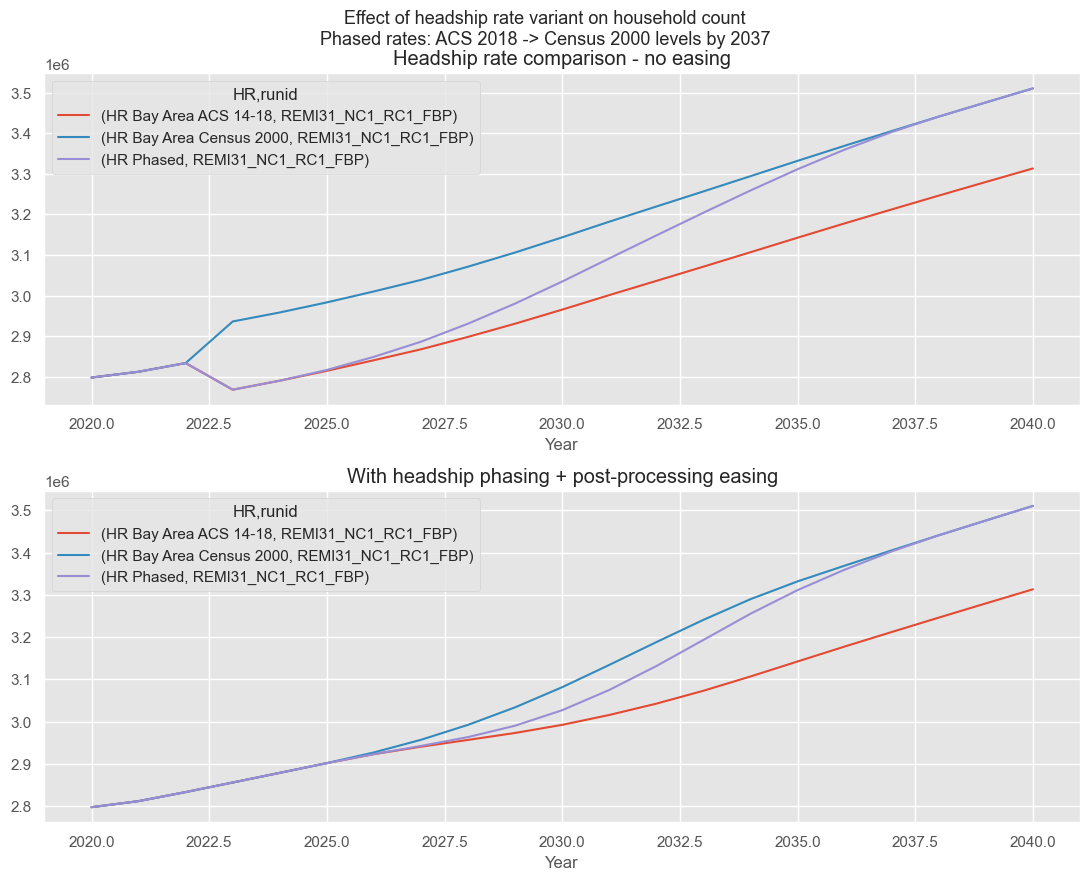

In [78]:
# Headship rate comparison: raw vs eased projections
fig, axs = plt.subplots(nrows=2, figsize=[11, 8.5])

hr_subset = ['HR Bay Area ACS 14-18', 'HR Phased', 'HR Bay Area Census 2000']
scen_qa   = 'REMI31_NC1_RC1_FBP'
years_qa  = list(range(2020, 2041))

(
    hhallscenarios.stack()
    .loc[hr_subset, scen_qa, :, years_qa]
    .groupby(level=['HR', 'runid', 'Year'])
    .sum()
    .unstack('Year').T
    .plot(ax=axs[0])
)
(
    hheaseallscenarios.stack()
    .loc[hr_subset, scen_qa, :, years_qa]
    .groupby(level=['HR', 'runid', 'Year'])
    .sum()
    .unstack('Year').T
    .plot(ax=axs[1])
)
axs[0].set_title('Headship rate comparison - no easing')
axs[1].set_title('With headship phasing + post-processing easing')
plt.tight_layout()
plt.suptitle(
    'Effect of headship rate variant on household count\n'
    'Phased rates: ACS 2018 -> Census 2000 levels by 2037',
    size=13, y=1.03,
)


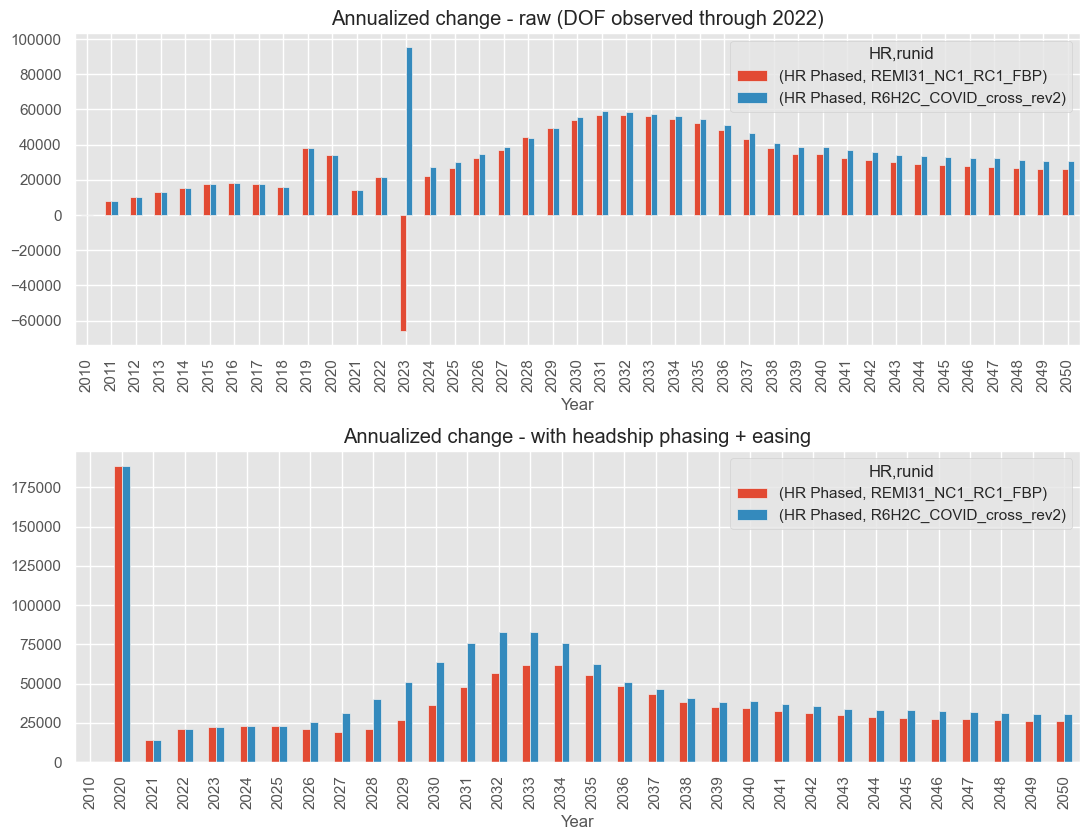

In [79]:
# Annualized change: check for jumps at the observed/modelled boundary
fig, axs = plt.subplots(nrows=2, figsize=[11, 8.5])
scens_qa = ['REMI31_NC1_RC1_FBP', 'R6H2C_COVID_cross_rev2']

(
    hhallscenarios.groupby(level=['HR', 'runid']).sum()
    .loc(0)[HR_TOPSHEET, scens_qa].T
    .diff()
    .plot(kind='bar', ax=axs[0])
)
(
    hheaseallscenarios.groupby(level=['HR', 'runid']).sum()
    .loc(0)[HR_TOPSHEET, scens_qa].T
    .diff()
    .plot(kind='bar', ax=axs[1])
)
axs[0].set_title('Annualized change - raw (DOF observed through %d)' % DOF_END_OVERRIDE)
axs[1].set_title('Annualized change - with headship phasing + easing')
plt.tight_layout()


<Axes: ylabel='age_grp_5'>

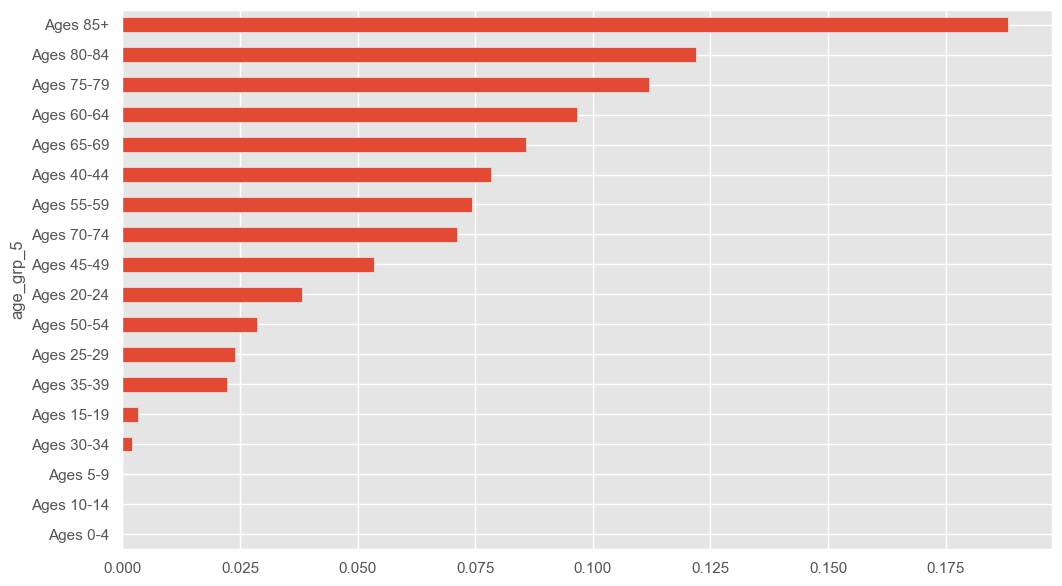

In [84]:
# We are growing most in senior households - the population is ageing and the older groups
# have higher headship rates

hhs_by_hh_head_age = hhallscenarios_age.loc['HR Phased','REMI31_NC1_RC1_FBP'].groupby(level=['age_grp_5']).sum()

# Calculate the change in households by age group between 2020 and 2050 and plot the distribution of changes
hhs_by_hh_head_age_bounds = hhs_by_hh_head_age[[2020,2050]]
(hhs_by_hh_head_age_bounds.diff(axis=1)[2050] / hhs_by_hh_head_age_bounds.diff(axis=1)[2050].sum()).sort_values().plot(kind='barh')


<Axes: ylabel='age_grp_5'>

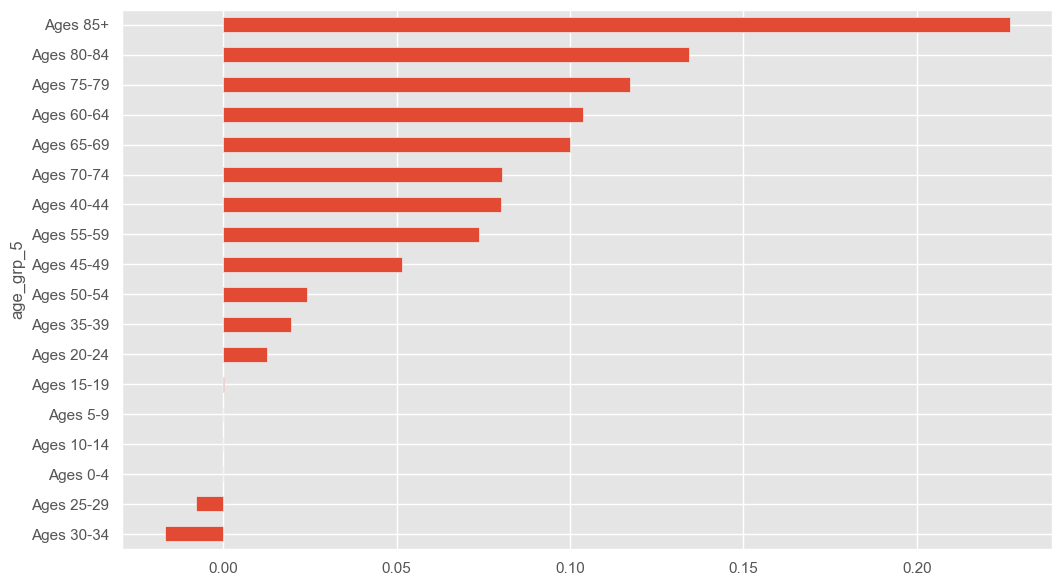

In [85]:
hhs_by_hh_head_age = hhallscenarios_age.loc['HR Bay Area ACS 14-18','REMI31_NC1_RC1_FBP'].groupby(level=['age_grp_5']).sum()
hhs_by_hh_head_age_bounds = hhs_by_hh_head_age[[2020,2050]]
(hhs_by_hh_head_age_bounds.diff(axis=1)[2050] / hhs_by_hh_head_age_bounds.diff(axis=1)[2050].sum()).sort_values().plot(kind='barh')
